## Laboratorio - Gestión de tareas con Heap y Cola de Prioridad

**Instrucción:** completa esta plantilla con tu diseño y desarrollo.


In [ ]:
# @title Ingrese datos
nombre_estudiante = "" # @param {"type":"string"}
carnet = None # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**

Un centro de cómputo recibe tareas que deben ser procesadas por sus servidores. Cada tarea tiene un **código**, un **nombre** y una **prioridad numérica**; las tareas con **mayor prioridad** deben procesarse primero.

Como las tareas llegan en cualquier orden y en cualquier momento, ordenar toda la lista cada vez que llega una tarea nueva sería ineficiente. La solución es una **cola de prioridad** implementada con un **Max-Heap almacenado en un arreglo**, que permite:

- Consultar la tarea más urgente en $O(1)$.
- Extraer (procesar) la tarea más urgente en $O(\log n)$.
- Insertar una tarea nueva en $O(\log n)$.
- Construir el heap inicial en $O(n)$ y ordenar las prioridades con **HeapSort** en $O(n \log n)$.

**Representación en arreglo** (índices desde 0): para un nodo en la posición `i`, su padre está en `(i-1)//2`, su hijo izquierdo en `2i+1` y su hijo derecho en `2i+2`. No se usan nodos ni punteros.

## 2) Requerimientos **[2 pts]**

### Funcionales
| ID | Requerimiento |
|---|---|
| RF1 | Solicitar al usuario `n` y registrar `n` tareas (código, nombre, prioridad), conservando el orden de ingreso. |
| RF2 | Mostrar la lista original de prioridades. |
| RF3 | Construir un Max-Heap con `MAX-HEAPIFY` y `BUILD-MAX-HEAP` y mostrarlo como arreglo y como árbol. |
| RF4 | `MAXIMUM`: mostrar la tarea de la raíz sin eliminarla. |
| RF5 | `EXTRACT-MAX`: retirar la tarea de mayor prioridad, mostrarla y reorganizar el heap. |
| RF6 | `INSERT`: agregar una nueva tarea conservando la propiedad de Max-Heap. |
| RF7 | `HEAPSORT`: ordenar las prioridades de forma ascendente, mostrando lista original, Max-Heap y lista ordenada. |
| RF8 | Probar el programa con al menos 6 tareas distintas. |

### No funcionales
| ID | Requerimiento |
|---|---|
| RNF1 | El heap se implementa con un **arreglo** (sin nodos ni punteros). |
| RNF2 | No usar `heapq`, ni `sort()` / `sorted()` en HeapSort. |
| RNF3 | Eficiencia: heapify $O(\log n)$, build $O(n)$, extract/insert $O(\log n)$, HeapSort $O(n\log n)$. |
| RNF4 | Código organizado por funciones, con nombres claros y comentarios. |
| RNF5 | Validar entradas (n entero positivo, prioridad entera) y manejar el heap vacío sin errores. |
| RNF6 | El notebook debe ser ejecutable de principio a fin y mostrar las salidas. |

## 3) Historias de usuario **[2 pts]**

**HU1 - Registrar tareas**  
*Como* operador del centro de cómputo, *quiero* registrar varias tareas con su código, nombre y prioridad, *para* que queden listas para ser organizadas.  
**Criterios de aceptación:**
- Dado que ingreso `n` tareas, el sistema guarda las `n` en el orden ingresado.
- El sistema muestra la lista original de prioridades, por ejemplo `[8, 4, 10, 3, 7]`.
- Si ingreso una prioridad que no es un entero, el sistema la vuelve a pedir.

**HU2 - Organizar las tareas por prioridad**  
*Como* operador, *quiero* que las tareas se organicen en un Max-Heap, *para* acceder rápido a la más urgente.  
**Criterios de aceptación:**
- Para toda posición `i`, la prioridad del padre es `>=` la de sus hijos.
- Para `[8, 4, 10, 3, 7]` el heap obtenido es `[10, 7, 8, 3, 4]`.
- El sistema muestra el heap como arreglo y como árbol.

**HU3 - Consultar y procesar la tarea más urgente**  
*Como* servidor del centro de cómputo, *quiero* consultar y procesar la tarea de mayor prioridad, *para* atender primero lo más importante.  
**Criterios de aceptación:**
- `MAXIMUM` muestra la raíz sin modificar el heap.
- `EXTRACT-MAX` retira la raíz, la muestra y el heap resultante sigue siendo válido (`[8, 7, 4, 3]` en el ejemplo).
- Si el heap está vacío, el sistema informa que no hay tareas en lugar de fallar.

**HU4 - Agregar tareas nuevas**  
*Como* operador, *quiero* insertar una tarea nueva en cualquier momento, *para* que sea atendida según su prioridad.  
**Criterios de aceptación:**
- Tras insertar una tarea con prioridad 12 en un heap cuyo máximo es menor, la nueva tarea queda en la raíz.
- Después de insertar, el heap sigue cumpliendo la propiedad de Max-Heap.

**HU5 - Obtener las prioridades ordenadas**  
*Como* analista, *quiero* ver las prioridades ordenadas de menor a mayor, *para* revisar la distribución de la carga.  
**Criterios de aceptación:**
- `HEAPSORT` de `[8, 4, 10, 3, 7]` devuelve `[3, 4, 7, 8, 10]`.
- Se muestran únicamente: lista original, Max-Heap y lista ordenada.
- No se usa `sort()` ni `sorted()`.

## 4) Diagramas de flujo **[5 pts]**
Diagrama del proceso general del programa (se genera con `matplotlib` y también se guarda como `diagrama_flujo.png`).

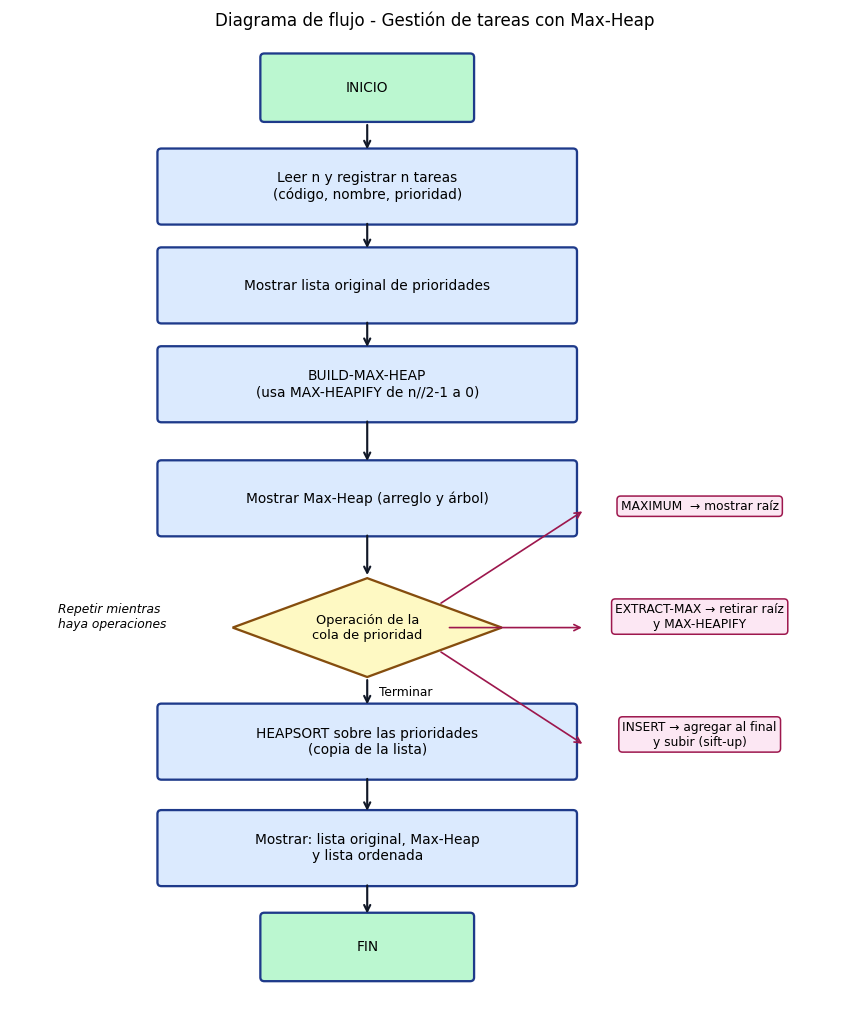

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Polygon

def caja(ax, x, y, texto, w=5.2, h=0.9, color="#dbeafe"):
    ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h, boxstyle="round,pad=0.05",
                                fc=color, ec="#1e3a8a", lw=1.5))
    ax.text(x, y, texto, ha="center", va="center", fontsize=9)

def ovalo(ax, x, y, texto):
    caja(ax, x, y, texto, w=2.6, h=0.8, color="#bbf7d0")

def rombo(ax, x, y, texto, w=3.4, h=1.3):
    ax.add_patch(Polygon([(x, y+h/2), (x+w/2, y), (x, y-h/2), (x-w/2, y)],
                         fc="#fef9c3", ec="#854d0e", lw=1.5))
    ax.text(x, y, texto, ha="center", va="center", fontsize=8.5)

def flecha(ax, x1, y1, x2, y2, texto=None):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", lw=1.4, color="#111827"))
    if texto:
        ax.text((x1+x2)/2 + 0.15, (y1+y2)/2, texto, fontsize=8, ha="left", va="center")

fig, ax = plt.subplots(figsize=(8, 9.5))
ax.set_xlim(-4.5, 6.2); ax.set_ylim(1.2, 14.2); ax.axis("off")

ys = [13.5, 12.2, 10.9, 9.6, 8.1, 6.4, 4.9, 3.5, 2.2]
ovalo(ax, 0, ys[0], "INICIO")
caja(ax, 0, ys[1], "Leer n y registrar n tareas\n(código, nombre, prioridad)")
caja(ax, 0, ys[2], "Mostrar lista original de prioridades")
caja(ax, 0, ys[3], "BUILD-MAX-HEAP\n(usa MAX-HEAPIFY de n//2-1 a 0)")
caja(ax, 0, ys[4], "Mostrar Max-Heap (arreglo y árbol)")
rombo(ax, 0, ys[5], "Operación de la\ncola de prioridad")
caja(ax, 0, ys[6], "HEAPSORT sobre las prioridades\n(copia de la lista)")
caja(ax, 0, ys[7], "Mostrar: lista original, Max-Heap\ny lista ordenada")
ovalo(ax, 0, ys[8], "FIN")

for a, b in [(0,1),(1,2),(2,3),(3,4)]:
    flecha(ax, 0, ys[a]-0.45, 0, ys[b]+0.45)
flecha(ax, 0, ys[4]-0.45, 0, ys[5]+0.65)
flecha(ax, 0, ys[5]-0.65, 0, ys[6]+0.45, "Terminar")
flecha(ax, 0, ys[6]-0.45, 0, ys[7]+0.45)
flecha(ax, 0, ys[7]-0.45, 0, ys[8]+0.4)

# Ramas de la operación (a la derecha) con retorno al rombo
ax.text(4.2, ys[5]+1.55, "MAXIMUM  → mostrar raíz", fontsize=8, ha="center",
        bbox=dict(boxstyle="round", fc="#fce7f3", ec="#9d174d"))
ax.text(4.2, ys[5]+0.0, "EXTRACT-MAX → retirar raíz\ny MAX-HEAPIFY", fontsize=8, ha="center",
        bbox=dict(boxstyle="round", fc="#fce7f3", ec="#9d174d"))
ax.text(4.2, ys[5]-1.55, "INSERT → agregar al final\ny subir (sift-up)", fontsize=8, ha="center",
        bbox=dict(boxstyle="round", fc="#fce7f3", ec="#9d174d"))
for yy in (ys[5]+1.55, ys[5], ys[5]-1.55):
    ax.annotate("", xy=(2.75, yy), xytext=(1.0, ys[5]) if yy==ys[5] else (0.9, ys[5]+(0.3 if yy>ys[5] else -0.3)),
                arrowprops=dict(arrowstyle="->", lw=1.1, color="#9d174d"))
ax.text(-3.9, ys[5]+0.0, "Repetir mientras\nhaya operaciones", fontsize=8, ha="left", style="italic")
plt.title("Diagrama de flujo - Gestión de tareas con Max-Heap", fontsize=11)
plt.tight_layout()
plt.savefig("diagrama_flujo.png", dpi=150)
plt.show()

**Descripción del diagrama:**

1. **Inicio** y lectura de `n` tareas (código, nombre, prioridad); se guardan en el orden de ingreso.
2. Se muestra la **lista original de prioridades**.
3. Se ejecuta **BUILD-MAX-HEAP**, que recorre los nodos internos desde `n//2 - 1` hasta `0` llamando a **MAX-HEAPIFY**.
4. Se muestra el **Max-Heap** como arreglo y como árbol.
5. El rombo representa las operaciones de la **cola de prioridad**, que pueden repetirse: `MAXIMUM` (solo consulta la raíz), `EXTRACT-MAX` (retira la raíz y reorganiza con `MAX-HEAPIFY`) e `INSERT` (agrega al final y sube el elemento hasta restaurar la propiedad).
6. Al terminar las operaciones se aplica **HEAPSORT** a las prioridades, se muestran lista original, Max-Heap y lista ordenada, y el programa **finaliza**.

### 5) Análisis de complejidad **[15 pts]**

**Justificación.** Un heap con `n` elementos es un árbol binario casi completo, por lo que su altura es $h = \lfloor \log_2 n \rfloor$.

| Operación | Justificación | Complejidad |
|---|---|---|
| `MAX-HEAPIFY` | En cada paso compara con 2 hijos y baja un nivel; a lo sumo recorre la altura. $T(n) \le T(2n/3) + \Theta(1)$ | $O(\log n)$ |
| `BUILD-MAX-HEAP` | Hay $\lceil n/2^{h+1} \rceil$ nodos de altura $h$ y cada uno cuesta $O(h)$: $\sum_{h=0}^{\log n} \frac{n}{2^{h+1}} h = O(n)$ | $O(n)$ |
| `MAXIMUM` | Lee `A[0]` | $O(1)$ |
| `EXTRACT-MAX` | Mueve el último a la raíz y llama a `MAX-HEAPIFY` | $O(\log n)$ |
| `INSERT` | Agrega al final y sube a lo sumo `h` niveles | $O(\log n)$ |
| `HEAPSORT` | `BUILD-MAX-HEAP` + `n-1` veces (intercambio + `MAX-HEAPIFY`) | $O(n \log n)$ |

**Función T(n) de HeapSort:**

$$T(n) = \underbrace{c_1 n}_{\text{BUILD-MAX-HEAP}} + \sum_{k=1}^{n-1} \big(c_2 + c_3 \cdot \text{altura}(k)\big) \;\le\; c_1 n + (n-1)(c_2 + c_3 \log_2 n) = \Theta(n \log n)$$

**Mejor caso:** todas las prioridades iguales. `MAX-HEAPIFY` nunca encuentra un hijo mayor y se detiene tras 2 comparaciones, así que $T(n) = \Theta(n)$.  
**Peor caso:** prioridades distintas; cada elemento colocado en la raíz debe bajar hasta casi las hojas, así que $T(n) = \Theta(n \log n)$.  
**Caso promedio:** $\Theta(n \log n)$.

La gráfica de abajo cuenta las **comparaciones reales** de nuestra implementación.

## 6) Código funcional **[15 pts]**

Cada tarea se guarda como una tupla `(codigo, nombre, prioridad)` dentro de una lista de Python usada como arreglo. La prioridad está en el índice `2`.

In [ ]:

PRIORIDAD = 2  

def padre(i): return (i - 1) // 2
def izquierdo(i): return 2 * i + 1
def derecho(i): return 2 * i + 2

def prioridades(A):
    """Devuelve la lista de prioridades de un arreglo de tareas."""
    return [t[PRIORIDAD] for t in A]

def texto_tarea(t):
    return f"{t[0]} - {t[1]}"

def leer_entero(mensaje, minimo=None):
    """Pide un entero por teclado y lo vuelve a pedir si no es válido."""
    while True:
        try:
            valor = int(input(mensaje))
            if minimo is not None and valor < minimo:
                print(f"  Debe ser mayor o igual a {minimo}.")
                continue
            return valor
        except ValueError:
            print("  Valor inválido, ingrese un número entero.")

def leer_tarea():
    codigo = input("  Código: ").strip()
    nombre = input("  Nombre: ").strip()
    prioridad = leer_entero("  Prioridad: ")
    return (codigo, nombre, prioridad)

def registrar_tareas():
    """Pide n y luego n tareas, conservando el orden de ingreso."""
    n = leer_entero("Cantidad de tareas: ", minimo=1)
    tareas = []
    for k in range(n):
        print(f"Tarea {k + 1}:")
        tareas.append(leer_tarea())
    return tareas

def max_heapify(A, i, tam, cont=None):
    """Hunde A[i] hasta que el subárbol con raíz i cumpla la propiedad de Max-Heap.
    tam = cantidad de elementos que forman parte del heap.
    cont = lista de un elemento para contar comparaciones (opcional)."""
    while True:
        l, r, mayor = izquierdo(i), derecho(i), i
        if l < tam:
            if cont is not None: cont[0] += 1
            if A[l][PRIORIDAD] > A[mayor][PRIORIDAD]:
                mayor = l
        if r < tam:
            if cont is not None: cont[0] += 1
            if A[r][PRIORIDAD] > A[mayor][PRIORIDAD]:
                mayor = r
        if mayor == i:
            return
        A[i], A[mayor] = A[mayor], A[i]
        i = mayor

def build_max_heap(A, cont=None):
    """Convierte el arreglo A en un Max-Heap (en el mismo arreglo)."""
    tam = len(A)
    for i in range(tam // 2 - 1, -1, -1):
        max_heapify(A, i, tam, cont)

def es_max_heap(A):
    """Verifica la propiedad: prioridad del padre >= prioridad de sus hijos."""
    return all(A[padre(i)][PRIORIDAD] >= A[i][PRIORIDAD] for i in range(1, len(A)))

def mostrar_arbol(A):
    """Dibuja el heap como árbol con texto (recorrido en orden para ubicar columnas)."""
    n = len(A)
    if n == 0:
        print("(heap vacío)")
        return
    ancho = max(len(str(t[PRIORIDAD])) for t in A) + 2
    col = {}
    contador = [0]
    def inorden(i, nivel):
        if i >= n: return
        inorden(izquierdo(i), nivel + 1)
        col[i] = (contador[0], nivel)
        contador[0] += 1
        inorden(derecho(i), nivel + 1)
    inorden(0, 0)
    niveles = max(v[1] for v in col.values()) + 1
    filas = [[" "] * (contador[0] * ancho + ancho) for _ in range(2 * niveles - 1)]
    def poner(fila, c, texto):
        for k, ch in enumerate(texto):
            filas[fila][c + k] = ch
    for i, (c, nivel) in col.items():
        etiqueta = str(A[i][PRIORIDAD])
        poner(2 * nivel, c * ancho + (ancho - len(etiqueta)) // 2, etiqueta)
        if i > 0:
            cp = col[padre(i)][0]
            medio = (c + cp) * ancho // 2 + ancho // 2
            filas[2 * nivel - 1][medio] = "/" if i % 2 == 1 else "\\"
    for f in filas:
        print("".join(f).rstrip())

def maximum(A):
    """MAXIMUM: devuelve la tarea de la raíz sin eliminarla."""
    if not A:
        raise IndexError("La cola de prioridad está vacía")
    return A[0]

def extract_max(A):
    """EXTRACT-MAX: retira y devuelve la tarea de mayor prioridad."""
    if not A:
        raise IndexError("La cola de prioridad está vacía")
    mayor = A[0]
    ultima = A.pop()          
    if A:                     
        A[0] = ultima
        max_heapify(A, 0, len(A))
    return mayor

def insertar(A, tarea):
    """INSERT: agrega la tarea al final y la sube mientras sea mayor que su padre."""
    A.append(tarea)
    i = len(A) - 1
    while i > 0 and A[padre(i)][PRIORIDAD] < A[i][PRIORIDAD]:
        A[i], A[padre(i)] = A[padre(i)], A[i]
        i = padre(i)
    return i                  

def _heapify_num(A, i, tam, cont=None):
    while True:
        l, r, mayor = 2 * i + 1, 2 * i + 2, i
        if l < tam:
            if cont is not None: cont[0] += 1
            if A[l] > A[mayor]: mayor = l
        if r < tam:
            if cont is not None: cont[0] += 1
            if A[r] > A[mayor]: mayor = r
        if mayor == i:
            return
        A[i], A[mayor] = A[mayor], A[i]
        i = mayor

def heapsort(lista, cont=None):
    """Ordena ascendentemente una COPIA de la lista usando HeapSort manual."""
    A = list(lista)
    n = len(A)
    for i in range(n // 2 - 1, -1, -1):      
        _heapify_num(A, i, n, cont)
    for fin in range(n - 1, 0, -1):          
        A[0], A[fin] = A[fin], A[0]
        _heapify_num(A, 0, fin, cont)
    return A

print("Funciones definidas correctamente.")

Funciones definidas correctamente.


### Ejecución del programa principal (Punto 5: prueba final)
Para que el notebook quede ejecutado y reproducible, los datos de la prueba se pasan directamente (6 tareas + 1 inserción). Al final hay una celda opcional que usa `registrar_tareas()` con entrada por teclado.

In [ ]:
print("=" * 60)
print("PUNTO 1 - REGISTRO DE TAREAS")
print("=" * 60)
tareas = [
    ("T01", "Compilar proyecto",  8),
    ("T02", "Generar backup",     4),
    ("T03", "Renderizar video",  10),
    ("T04", "Procesar correos",   3),
    ("T05", "Ejecutar pruebas",   7),
    ("T07", "Enviar reportes",    6),
]
for t in tareas:
    print(f"  {t[0]} - {t[1]} - Prioridad {t[2]}")
original = prioridades(tareas)
print("\nLista original de prioridades:", original)

PUNTO 1 - REGISTRO DE TAREAS
  T01 - Compilar proyecto - Prioridad 8
  T02 - Generar backup - Prioridad 4
  T03 - Renderizar video - Prioridad 10
  T04 - Procesar correos - Prioridad 3
  T05 - Ejecutar pruebas - Prioridad 7
  T07 - Enviar reportes - Prioridad 6

Lista original de prioridades: [8, 4, 10, 3, 7, 6]


In [ ]:
print("=" * 60)
print("PUNTO 2 - CONSTRUCCIÓN DEL MAX-HEAP")
print("=" * 60)
heap = list(tareas)          
build_max_heap(heap)
print("Lista original:", original)
print("Max-Heap:      ", prioridades(heap))
print("¿Cumple la propiedad de Max-Heap?", es_max_heap(heap))
print("\nÁrbol:")
mostrar_arbol(heap)

print("\n--- Ejemplo del enunciado ---")
ej = [("A", "a", 8), ("B", "b", 4), ("C", "c", 10), ("D", "d", 3), ("E", "e", 7)]
print("Lista original: [8, 4, 10, 3, 7]")
build_max_heap(ej)
print("Max-Heap:", prioridades(ej))
mostrar_arbol(ej)

PUNTO 2 - CONSTRUCCIÓN DEL MAX-HEAP
Lista original: [8, 4, 10, 3, 7, 6]
Max-Heap:       [10, 7, 8, 3, 4, 6]
¿Cumple la propiedad de Max-Heap? True

Árbol:
             10
          /       \
     7               8
    /   \           /
 3       4       6

--- Ejemplo del enunciado ---
Lista original: [8, 4, 10, 3, 7]
Max-Heap: [10, 7, 8, 3, 4]
             10
          /     \
     7           8
    /   \
 3       4


In [ ]:
print("=" * 60)
print("PUNTO 3 - COLA DE PRIORIDAD")
print("=" * 60)

print("\nA. MAXIMUM")
t = maximum(heap)
print(f"Tarea de mayor prioridad: {texto_tarea(t)}  Prioridad: {t[PRIORIDAD]}")
print("Heap sin cambios:", prioridades(heap))

print("\nB. EXTRACT-MAX")
t = extract_max(heap)
print(f"Tarea procesada: {texto_tarea(t)}  (Prioridad {t[PRIORIDAD]})")
print("Nuevo Heap:", prioridades(heap), "| válido:", es_max_heap(heap))
mostrar_arbol(heap)

print("\nC. INSERT")
nueva = ("T06", "Actualizar servidor", 12)
print(f"Insertando -> Código: {nueva[0]}  Nombre: {nueva[1]}  Prioridad: {nueva[2]}")
pos = insertar(heap, nueva)
print("Heap tras insertar:", prioridades(heap), "| válido:", es_max_heap(heap))
print(f"La prioridad 12 quedó en la posición {pos} del arreglo.")
mostrar_arbol(heap)

t = maximum(heap)
print(f"\nNueva tarea de mayor prioridad: {texto_tarea(t)}  Prioridad: {t[PRIORIDAD]}")

PUNTO 3 - COLA DE PRIORIDAD

A. MAXIMUM
Tarea de mayor prioridad: T03 - Renderizar video  Prioridad: 10
Heap sin cambios: [10, 7, 8, 3, 4, 6]

B. EXTRACT-MAX
Tarea procesada: T03 - Renderizar video  (Prioridad 10)
Nuevo Heap: [8, 7, 6, 3, 4] | válido: True
          8
       /   \
    7        6
  /  \
 3     4

C. INSERT
Insertando -> Código: T06  Nombre: Actualizar servidor  Prioridad: 12
Heap tras insertar: [12, 7, 8, 3, 4, 6] | válido: True
La prioridad 12 quedó en la posición 0 del arreglo.
             12
          /       \
     7               8
    /   \           /
 3       4       6

Nueva tarea de mayor prioridad: T06 - Actualizar servidor  Prioridad: 12


In [ ]:
print("=" * 60)
print("PUNTO 4 - HEAPSORT")
print("=" * 60)
lista = prioridades(tareas)
heap_inicial = list(tareas)
build_max_heap(heap_inicial)
max_heap_prior = prioridades(heap_inicial)
ordenada = heapsort(lista)
print("Lista original:", lista)
print("Max-Heap:      ", max_heap_prior)
print("Lista ordenada:", ordenada)

print("\nEjemplo del enunciado:", heapsort([8, 4, 10, 3, 7]))

PUNTO 4 - HEAPSORT
Lista original: [8, 4, 10, 3, 7, 6]
Max-Heap:       [10, 7, 8, 3, 4, 6]
Lista ordenada: [3, 4, 6, 7, 8, 10]

Ejemplo del enunciado: [3, 4, 7, 8, 10]


In [ ]:
print("Tareas que quedaron en la cola tras las operaciones:", prioridades(heap))
print("Procesando toda la cola en orden de prioridad (EXTRACT-MAX repetido):")
cola = list(heap)
while cola:
    t = extract_max(cola)
    print(f"  {texto_tarea(t)} (Prioridad {t[PRIORIDAD]})")
print("Cola vacía:", cola)
try:
    extract_max(cola)
except IndexError as e:
    print("Intento sobre cola vacía controlado ->", e)

Tareas que quedaron en la cola tras las operaciones: [12, 7, 8, 3, 4, 6]
Procesando toda la cola en orden de prioridad (EXTRACT-MAX repetido):
  T06 - Actualizar servidor (Prioridad 12)
  T01 - Compilar proyecto (Prioridad 8)
  T05 - Ejecutar pruebas (Prioridad 7)
  T07 - Enviar reportes (Prioridad 6)
  T02 - Generar backup (Prioridad 4)
  T04 - Procesar correos (Prioridad 3)
Cola vacía: []
Intento sobre cola vacía controlado -> La cola de prioridad está vacía


In [8]:
# (Opcional) Ejecución interactiva con entrada por teclado.
# Quite el comentario para usarla; el notebook entregado ya fue ejecutado con datos de prueba.
# tareas_usuario = registrar_tareas()
# print("Lista original de prioridades:", prioridades(tareas_usuario))
# h = list(tareas_usuario); build_max_heap(h)
# print("Max-Heap:", prioridades(h)); mostrar_arbol(h)

### Gráfica del mejor y peor caso de HeapSort
Se cuentan las comparaciones realizadas por `heapsort` para distintos tamaños. Mejor caso = todas las prioridades iguales; peor caso = prioridades distintas (orden aleatorio, que en la práctica alcanza el comportamiento $n\log n$). Se comparan contra $n$ y $2n\log_2 n$.

     n   mejor (comp.)    peor (comp.)   2n·log2(n)
    50             144             423          564
   100             294            1024         1328
   200             594            2473         3057
   400            1194            5730         6915
   800            2394           13042        15430
  1600            4794           29225        34060
  3200            9594           64775        74520


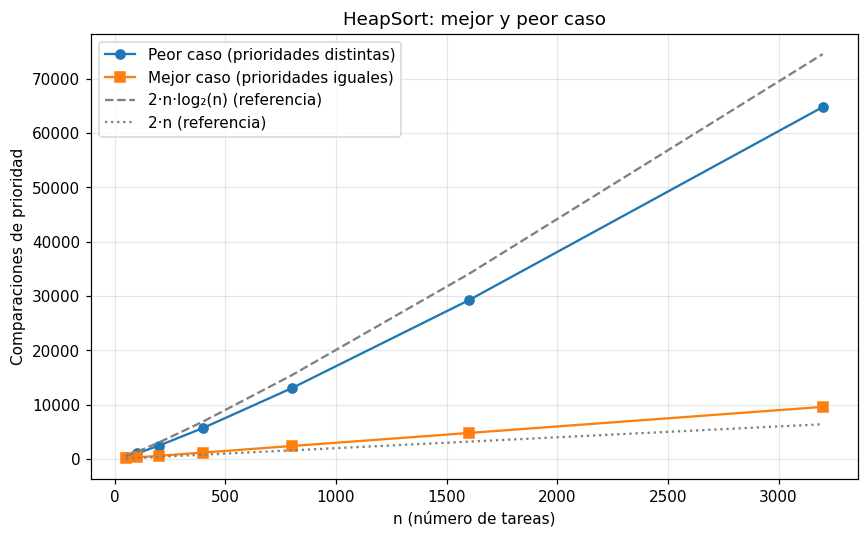

In [ ]:
import random, math
import matplotlib.pyplot as plt

tamanos = [50, 100, 200, 400, 800, 1600, 3200]
mejor, peor = [], []
random.seed(42)
for n in tamanos:
    c = [0]; heapsort([5] * n, c); mejor.append(c[0])              
    c = [0]; heapsort(random.sample(range(10 * n), n), c); peor.append(c[0])  

print(f"{'n':>6} {'mejor (comp.)':>15} {'peor (comp.)':>15} {'2n·log2(n)':>12}")
for n, m, p in zip(tamanos, mejor, peor):
    print(f"{n:>6} {m:>15} {p:>15} {int(2*n*math.log2(n)):>12}")

plt.figure(figsize=(8, 5))
plt.plot(tamanos, peor, "o-", label="Peor caso (prioridades distintas)")
plt.plot(tamanos, mejor, "s-", label="Mejor caso (prioridades iguales)")
plt.plot(tamanos, [2 * n * math.log2(n) for n in tamanos], "--", color="gray", label="2·n·log₂(n) (referencia)")
plt.plot(tamanos, [2 * n for n in tamanos], ":", color="gray", label="2·n (referencia)")
plt.xlabel("n (número de tareas)"); plt.ylabel("Comparaciones de prioridad")
plt.title("HeapSort: mejor y peor caso"); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.savefig("grafica_complejidad.png", dpi=150); plt.show()

**Interpretación:** el mejor caso crece de forma lineal ($\Theta(n)$) y el peor caso sigue la curva de $n \log n$, tal como predice el análisis teórico.

## 7) Tests aplicados **[15 pts]**

Pruebas con `assert` sobre cada función: casos del enunciado, casos borde (1 elemento, vacío, duplicados) y pruebas aleatorias que verifican la propiedad de Max-Heap sin usar `sort()` ni `sorted()`.

In [ ]:
from collections import Counter
import random

def T(*prios):
    """Crea tareas de prueba a partir de una lista de prioridades."""
    return [(f"T{k}", f"tarea{k}", p) for k, p in enumerate(prios)]

def esta_ordenada(L):
    return all(L[i] <= L[i + 1] for i in range(len(L) - 1))


A = T(8, 4, 10, 3, 7); build_max_heap(A)
assert prioridades(A) == [10, 7, 8, 3, 4]; assert es_max_heap(A)
print("OK 1: build_max_heap([8,4,10,3,7]) == [10,7,8,3,4]")


A = T(1, 9, 8, 4, 5, 6, 7); max_heapify(A, 0, len(A))
assert prioridades(A) == [9, 5, 8, 4, 1, 6, 7] and es_max_heap(A)
print("OK 2: max_heapify repara la raíz")


A = T(8, 4, 10, 3, 7); build_max_heap(A); antes = list(A)
assert maximum(A)[PRIORIDAD] == 10 and A == antes
print("OK 3: maximum devuelve la raíz sin eliminarla")


extraida = extract_max(A)
assert extraida[PRIORIDAD] == 10 and prioridades(A) == [8, 7, 4, 3] and es_max_heap(A)
print("OK 4: extract_max -> tarea 10 y nuevo heap [8,7,4,3]")


pos = insertar(A, ("T06", "Actualizar servidor", 12))
assert pos == 0 and A[0][PRIORIDAD] == 12 and es_max_heap(A) and len(A) == 5
print("OK 5: insertar prioridad 12 -> raíz;", prioridades(A))

B = T(10, 7, 8); pos = insertar(B, ("X", "x", 1))
assert pos == 3 and es_max_heap(B)
print("OK 6: insertar prioridad menor queda como hoja")

orig = [8, 4, 10, 3, 7]
assert heapsort(orig) == [3, 4, 7, 8, 10] and orig == [8, 4, 10, 3, 7]
print("OK 7: heapsort([8,4,10,3,7]) == [3,4,7,8,10]")

assert heapsort([]) == [] and heapsort([5]) == [5]
assert heapsort([2, 2, 2]) == [2, 2, 2]
assert heapsort([5, 4, 3, 2, 1]) == [1, 2, 3, 4, 5]
assert heapsort([1, 2, 3, 4, 5]) == [1, 2, 3, 4, 5]
assert heapsort([-3, 0, 7, -3, 7]) == [-3, -3, 0, 7, 7]
print("OK 8: vacío, un elemento, duplicados, inverso, ordenado y negativos")

vacio = []
build_max_heap(vacio); assert vacio == []
for operacion in (maximum, extract_max):
    try:
        operacion([]); assert False, "debió lanzar IndexError"
    except IndexError:
        pass
unico = T(5); assert extract_max(unico)[PRIORIDAD] == 5 and unico == []
print("OK 9: heap vacío y de un elemento")

D = T(5, 5, 5, 5); build_max_heap(D); assert es_max_heap(D)
extract_max(D); assert es_max_heap(D) and len(D) == 3
print("OK 10: prioridades repetidas")

A = T(8, 4, 10, 3, 7, 6, 12, 1); build_max_heap(A)
salida = []
while A:
    salida.append(extract_max(A)[PRIORIDAD])
assert salida == [12, 10, 8, 7, 6, 4, 3, 1]
print("OK 11: extract_max repetido ->", salida)

random.seed(7)
for _ in range(500):
    n = random.randint(0, 40)
    datos = [random.randint(-20, 20) for _ in range(n)]
    H = T(*datos); build_max_heap(H)
    assert es_max_heap(H) and Counter(prioridades(H)) == Counter(datos)
    for p in datos[:5]:
        insertar(H, ("N", "n", p)); assert es_max_heap(H)
    if H:
        extract_max(H); assert es_max_heap(H)
    r = heapsort(datos)
    assert esta_ordenada(r) and Counter(r) == Counter(datos)
print("OK 12: 500 pruebas aleatorias de build, insert, extract y heapsort")

print("\n✔ Todos los tests pasaron.")

OK 1: build_max_heap([8,4,10,3,7]) == [10,7,8,3,4]
OK 2: max_heapify repara la raíz
OK 3: maximum devuelve la raíz sin eliminarla
OK 4: extract_max -> tarea 10 y nuevo heap [8,7,4,3]
OK 5: insertar prioridad 12 -> raíz; [12, 8, 4, 3, 7]
OK 6: insertar prioridad menor queda como hoja
OK 7: heapsort([8,4,10,3,7]) == [3,4,7,8,10]
OK 8: vacío, un elemento, duplicados, inverso, ordenado y negativos
OK 9: heap vacío y de un elemento
OK 10: prioridades repetidas
OK 11: extract_max repetido -> [12, 10, 8, 7, 6, 4, 3, 1]
OK 12: 500 pruebas aleatorias de build, insert, extract y heapsort

✔ Todos los tests pasaron.
